In [4]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('insurance.csv')

#Visualization & Preprocessing

In [6]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

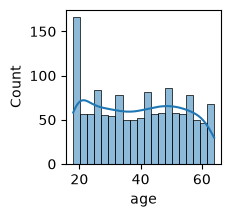

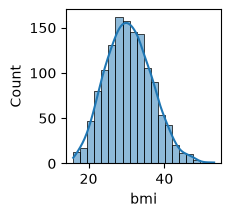

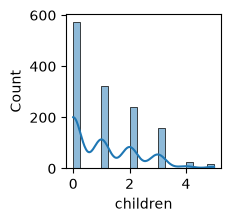

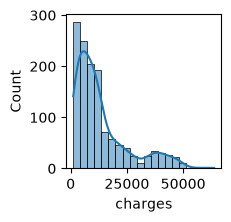

In [7]:
numeric_cols=['age', 'bmi', 'children', 'charges']
for col in numeric_cols:
    plt.figure(figsize=(2,2))
    sns.histplot(df[col], kde=True, bins=20)

<Axes: xlabel='children', ylabel='count'>

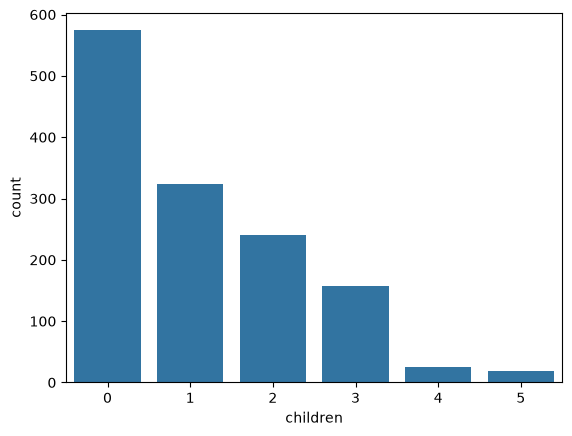

In [8]:
sns.countplot(x=df['children'])

<Axes: xlabel='sex', ylabel='count'>

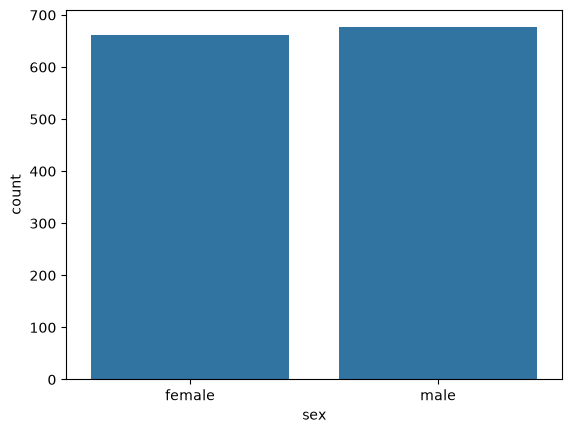

In [9]:
sns.countplot(x=df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

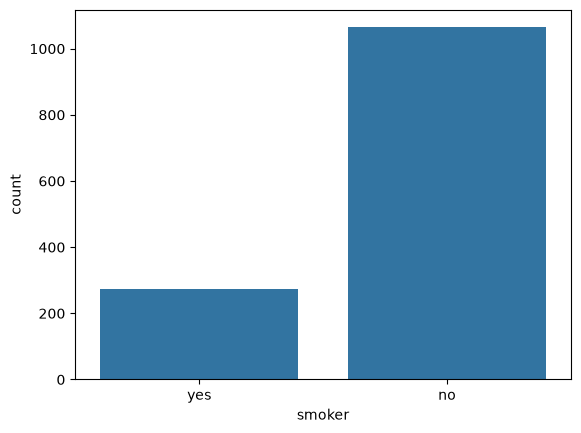

In [10]:
sns.countplot(x=df['smoker'])

<Axes: >

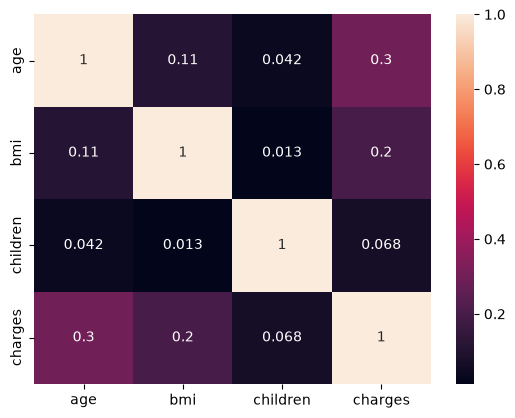

In [11]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [12]:
df.drop_duplicates(inplace=True)
df.shape

(1337, 7)

Encoding

In [13]:
df['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [14]:
df['sex'] = df['sex'].map({'male':0, 'female':1})
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [15]:
df['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [16]:
df['smoker'] = df['smoker'].map({'yes' : 1, 'no' : 0})
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [17]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

One-Hot Encoding

In [18]:
df_clean = pd.get_dummies(df, columns=['region'], drop_first=True, dtype='int')
df_clean.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,1
1,18,0,33.770,1,0,1725.55230,0,1,0
2,28,0,33.000,3,0,4449.46200,0,1,0
3,33,0,22.705,0,0,21984.47061,1,0,0
4,32,0,28.880,0,0,3866.85520,1,0,0


In [19]:
df_clean['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 24.9, 29.9, float('inf')], labels= ['Underweight', 'Normal', 'Overweight', 'Obese'])
df_clean.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,1,16884.92400,0,0,1,Overweight
1,18,0,33.770,1,0,1725.55230,0,1,0,Obese
2,28,0,33.000,3,0,4449.46200,0,1,0,Obese
3,33,0,22.705,0,0,21984.47061,1,0,0,Normal
4,32,0,28.880,0,0,3866.85520,1,0,0,Overweight


<Axes: xlabel='bmi_category', ylabel='Count'>

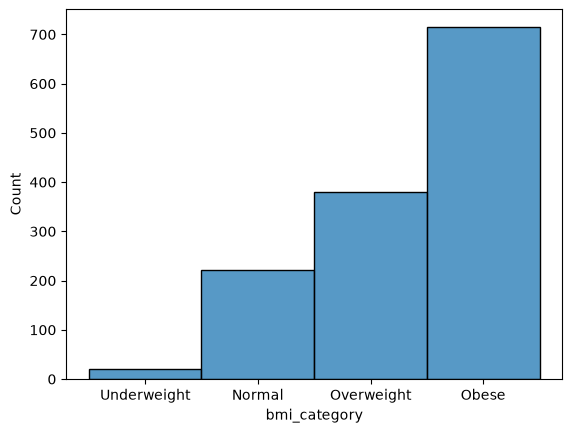

In [20]:
sns.histplot(df_clean['bmi_category'])

In [21]:
df_clean = pd.get_dummies(df_clean, columns=['bmi_category'], drop_first=True, dtype=int)
df_clean.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27.900,0,1,16884.92400,0,0,1,0,1,0
1,18,0,33.770,1,0,1725.55230,0,1,0,0,0,1
2,28,0,33.000,3,0,4449.46200,0,1,0,0,0,1
3,33,0,22.705,0,0,21984.47061,1,0,0,1,0,0
4,32,0,28.880,0,0,3866.85520,1,0,0,0,1,0


Pearson Correlation Check 

In [22]:
from scipy.stats import pearsonr

In [25]:
selected_features = ['age', 'sex', 'bmi', 'children', 'smoker',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese']
corr = {feature : pearsonr(df_clean[feature], df_clean['charges'])[0] 
       for feature in selected_features}
df_corr = pd.DataFrame(corr.items(), columns= ['Feature', 'Correlation']).sort_values(by='Correlation', ascending=False)
df_corr

,Feature,Correlation
4,smoker,0.787234
0,age,0.298308
2,bmi,0.198401
10,bmi_category_Obese,0.197659
6,region_southeast,0.073578
3,children,0.067389
5,region_northwest,-0.038695
7,region_southwest,-0.043637
1,sex,-0.058044
8,bmi_category_Normal,-0.105655
